# Termômetro Cidadão
**Global Solution 2026.2 (CitizenTech) - FIAP** · grupo Cluster 2.0 · turma 2TSCOR

O calor extremo não derruba casas nem alaga ruas, por isso quase não vira manchete. Mas ele desidrata, agrava doenças do coração e dos rins e mata, principalmente idoso. O alerta de calor que existe hoje chega para quem já está conectado em app ou segue o canal da prefeitura. Quem mais precisa normalmente é quem menos recebe.

A proposta aqui é simples: separar o calor em **tipos de dia** (nem todo calor é igual, o seco desidrata, o abafado sobrecarrega o corpo porque o suor não evapora) e cruzar isso com a **vulnerabilidade** de cada município (proporção de idosos). Onde um calor perigoso encontra muita gente vulnerável, o alerta vira prioridade e busca ativa.

Este notebook faz o caminho inteiro: dos dados brutos do INMET até o data warehouse que alimenta o dashboard. Fontes: estações automáticas do **INMET** (2023 a 2025) e **Censo 2022 do IBGE** (tabela 9514, população por idade).

In [1]:
import numpy as np
import pandas as pd
import unicodedata as U
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

DADOS = '../dados'
pd.set_option('display.width', 120)

## 1. Os dados diários

Cada estação do INMET gera medições de hora em hora. A gente já consolidou isso por estação e por dia em `estacoes_diario.csv.gz`: temperatura máxima e mínima, umidade relativa média e o índice de calor máximo do dia.

O **índice de calor** é o que o corpo "sente" quando junta temperatura e umidade. Calculamos pela fórmula da NWS (abaixo) a cada hora e guardamos o máximo do dia (`himax`). É ele, mais que a temperatura pura, que explica o risco à saúde.

In [2]:
def indice_calor(T, UR):
    """Índice de calor (NWS Rothfusz), entrada e saída em graus Celsius."""
    Tf = T * 9/5 + 32
    if Tf < 80:
        return (Tf - 32) * 5/9
    hi = (-42.379 + 2.04901523*Tf + 10.14333127*UR - 0.22475541*Tf*UR
          - 6.83783e-3*Tf**2 - 5.481717e-2*UR**2 + 1.22874e-3*Tf**2*UR
          + 8.5282e-4*Tf*UR**2 - 1.99e-6*Tf**2*UR**2)
    if UR < 13 and 80 <= Tf <= 112:
        hi -= ((13-UR)/4) * np.sqrt((17-abs(Tf-95))/17)
    elif UR > 85 and 80 <= Tf <= 87:
        hi += ((UR-85)/10) * ((87-Tf)/5)
    return (hi - 32) * 5/9

# 35 graus com 60% de umidade "sentidos" como:
round(indice_calor(35, 60), 1)

45.1

In [3]:
bruto = pd.read_csv(f'{DADOS}/estacoes_diario.csv.gz', parse_dates=['d'])
# fica só com dias cheios (ao menos 19 das 24 horas) e sem buraco nas variáveis
d = bruto[(bruto.n >= 19) & bruto[['tmax','tmin','rh','himax']].notna().all(axis=1)]
d = d.sort_values(['cod','d']).reset_index(drop=True)
print(d.shape[0], 'dias-estação válidos |', bruto.cod.nunique(), 'estações |', sorted(d.d.dt.year.unique()))
d[['d','cod','uf','tmax','tmin','rh','himax']].head()

458167 dias-estação válidos | 599 estações | [np.int32(2023), np.int32(2024), np.int32(2025)]


,d,cod,uf,tmax,tmin,rh,himax
0,2023-01-01,A001,DF,27.8,18.1,76.791667,27.564692
1,2023-01-02,A001,DF,28.2,19.7,67.958333,28.120703
2,2023-01-03,A001,DF,27.9,18.1,81.000000,28.093169
3,2023-01-04,A001,DF,26.0,17.7,81.250000,25.342222
4,2023-01-05,A001,DF,25.9,18.8,79.875000,25.148333


## 2. Atributos do dia

Além de temperatura, umidade e índice de calor, o que faz um calor virar problema de saúde pública é a **persistência**: vários dias quentes seguidos sem a casa esfriar, e principalmente **noites quentes** (corpo não descansa). Então contamos duas sequências por estação:

- `seqd`: dias seguidos com máxima >= 32 graus
- `seqn`: noites seguidas com mínima >= 22 graus

Cortamos em 14 porque acima disso já é "onda de calor prolongada" de qualquer jeito.

In [4]:
def sequencia(mask):
    # reinicia a contagem quando muda a estação, pula um dia ou quebra a condição
    grupo = ((d.groupby('cod').d.diff().dt.days != 1) | (mask != mask.shift()) | (d.cod != d.cod.shift())).cumsum()
    return np.where(mask, mask.groupby(grupo).cumsum(), 0)

d['seqd'] = np.clip(sequencia(d.tmax >= 32), 0, 14)
d['seqn'] = np.clip(sequencia(d.tmin >= 22), 0, 14)
d[['tmax','tmin','seqd','seqn']].describe().round(1).loc[['mean','max']]

,tmax,tmin,seqd,seqn
mean,30.1,19.1,2.7,2.4
max,44.5,33.5,14.0,14.0


## 3. Quantos tipos de dia existem?

Vamos agrupar os dias com k-means. Antes, duas decisões:

1. **Padronizar** as variáveis (z-score), senão a temperatura domina tudo só por ter números maiores.
2. **Pesar** depois da padronização. A umidade ganha peso maior (1.4) porque é ela que separa o calor seco do abafado, que é justamente a distinção que muda a mensagem do alerta. As sequências pesam menos (0.5) para não estourar os poucos dias de onda de calor.

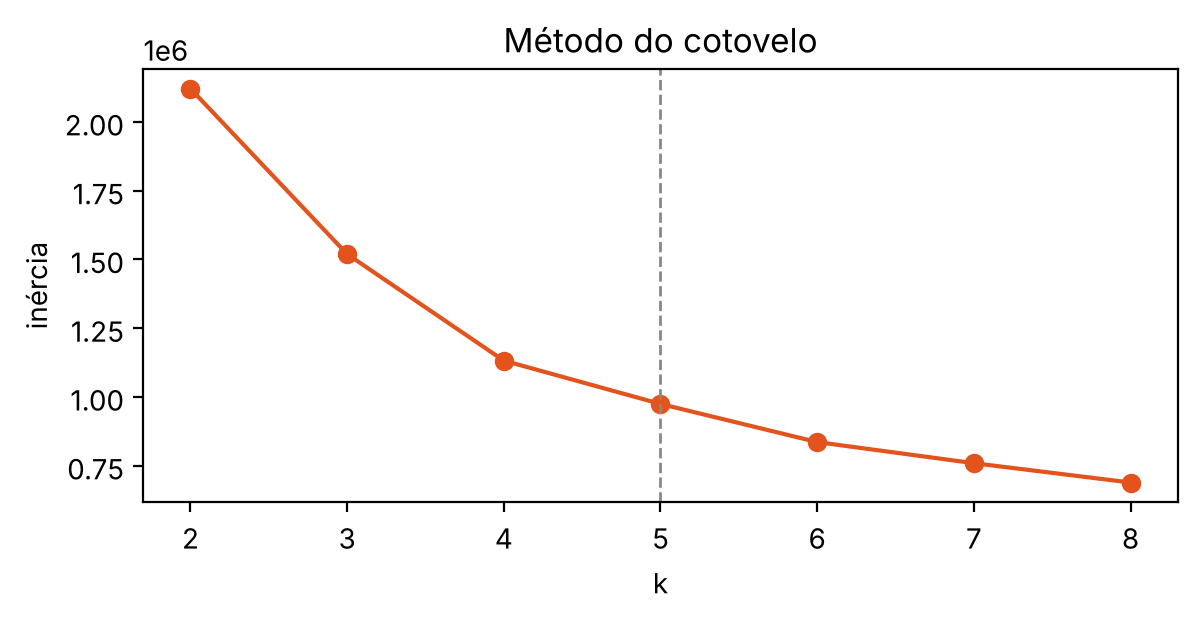

In [5]:
feat = np.c_[d.tmax, d.tmin, d.rh, d.himax, d.seqd, d.seqn]
pesos = np.array([1, 1.1, 1.4, 1, 0.5, 1.2])   # tmax, tmin, rh, himax, seqd, seqn
Z = StandardScaler().fit_transform(feat) * pesos

# método do cotovelo
inercia = []
Ks = range(2, 9)
for k in Ks:
    inercia.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z).inertia_)

plt.figure(figsize=(6,3.2))
plt.plot(list(Ks), inercia, 'o-', color='#e2531d')
plt.axvline(5, ls='--', color='#888', lw=1)
plt.title('Método do cotovelo'); plt.xlabel('k'); plt.ylabel('inércia'); plt.tight_layout(); plt.show()

In [6]:
# silhueta num sub-conjunto (o dataset todo é grande demais para o cálculo O(n^2))
amostra = np.random.RandomState(1).choice(len(Z), 20000, replace=False)
for k in [4, 5, 6]:
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)
    print(f'k={k}  silhueta={silhouette_score(Z[amostra], lab[amostra]):.3f}')

k=4  silhueta=0.336


k=5  silhueta=0.323


k=6  silhueta=0.307


O cotovelo amassa perto de 5 e a silhueta fica estável. Cinco tipos também é o que dá para explicar numa cartilha de prefeitura sem virar tabela de 12 linhas. Fechamos em **k = 5**.

In [7]:
km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(Z)
d['k'] = km.labels_
sil = silhouette_score(Z[amostra], km.labels_[amostra])
print('silhueta final:', round(sil, 3))

perfil = d.groupby('k').agg(tmax=('tmax','mean'), tmin=('tmin','mean'), rh=('rh','mean'),
                            hi=('himax','mean'), seqd=('seqd','mean'), seqn=('seqn','mean'))
perfil.round(1)

silhueta final: 0.323


,tmax,tmin,rh,hi,seqd,seqn
k,,,,,,
0,35.3,20.9,52.0,34.3,7.9,1.3
1,21.8,13.2,83.8,21.1,0.0,0.0
2,33.2,24.0,75.6,36.7,5.4,12.8
3,28.9,15.2,63.0,27.7,0.3,0.0
4,30.7,20.7,79.2,32.4,1.4,0.7


## 4. Dando nome aos cinco tipos

Os clusters saem numerados sem significado. A gente batiza cada um pelo perfil do centroide, com regra fixa (sem escolher na mão):

- o mais frio de todos é **Frio ou ameno**;
- dos quatro que sobram, os dois com maior temperatura são os calores fortes. Entre eles, o de menor umidade é **Calor seco** e o outro é **Calor abafado**;
- dos dois do meio, o mais seco é **Ameno e seco** e o outro é **Quente e úmido**.

E cada tipo recebe uma categoria de alerta (1 sem alerta, 2 atenção, 3 risco alto).

In [8]:
frio = perfil.tmax.idxmin()
resto = perfil.drop(frio)
quentes = resto.tmax.nlargest(2).index.tolist()
meio = [k for k in resto.index if k not in quentes]
seco = perfil.loc[quentes].rh.idxmin();         abafado = [k for k in quentes if k != seco][0]
ameno_seco = perfil.loc[meio].rh.idxmin();       quente_umido = [k for k in meio if k != ameno_seco][0]

tipos = {frio:('Frio ou ameno',1), ameno_seco:('Ameno e seco',1), quente_umido:('Quente e úmido',2),
         seco:('Calor seco',3), abafado:('Calor abafado',3)}
ordem = [frio, ameno_seco, quente_umido, seco, abafado]
id_tipo = {k:i+1 for i,k in enumerate(ordem)}

d['id_tipo_dia'] = d.k.map(id_tipo)
d['id_categoria'] = d.k.map(lambda x: tipos[x][1])

tab = perfil.loc[ordem].copy()
tab.index = [tipos[k][0] for k in ordem]
print('participação de cada tipo nos', len(d), 'dias:')
(d.id_tipo_dia.value_counts(normalize=True).sort_index()*100).round(1)

participação de cada tipo nos 458167 dias:


id_tipo_dia
1    15.7
2    17.0
3    35.4
4    17.2
5    14.8
Name: proportion, dtype: float64

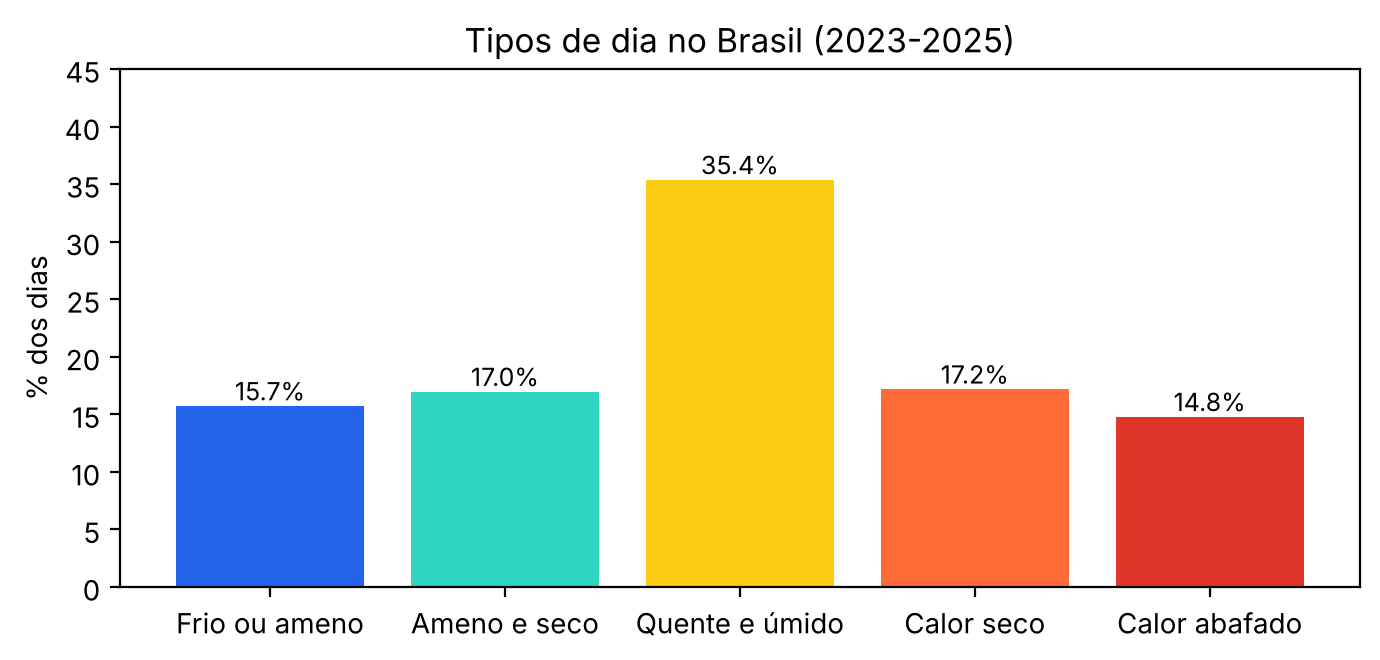

,tmax,tmin,rh,hi,seqd,seqn
Frio ou ameno,21.8,13.2,83.8,21.1,0.0,0.0
Ameno e seco,28.9,15.2,63.0,27.7,0.3,0.0
Quente e úmido,30.7,20.7,79.2,32.4,1.4,0.7
Calor seco,35.3,20.9,52.0,34.3,7.9,1.3
Calor abafado,33.2,24.0,75.6,36.7,5.4,12.8


In [9]:
cores = ['#2563eb','#2dd4bf','#facc15','#ff6b35','#e0352b']
share = (d.id_tipo_dia.value_counts(normalize=True).sort_index()*100)
plt.figure(figsize=(7,3.4))
plt.bar([tipos[k][0] for k in ordem], share.values, color=cores)
for i,v in enumerate(share.values): plt.text(i, v+0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.title('Tipos de dia no Brasil (2023-2025)'); plt.ylabel('% dos dias'); plt.ylim(0,45)
plt.tight_layout(); plt.show()
tab.round(1)

Dá para ver os dois calores de risco (seco e abafado) e a diferença entre eles: o seco tem umidade perto de 52% e sequências longas de dias quentes; o abafado tem umidade alta e, principalmente, **noites quentes seguidas** (`seqn` bem maior), que é o que mais mata idoso.

## 5. Vulnerabilidade: quem o calor atinge primeiro

O tipo de dia é metade da conta. A outra metade é quem vive ali. Usamos a proporção de pessoas com **65 anos ou mais** por município (Censo 2022). Primeiro ligamos cada município à estação meteorológica mais próxima (distância de Haversine), depois trazemos os idosos do IBGE.

In [10]:
mun = pd.read_csv(f'{DADOS}/municipios_ibge.csv')
est = pd.read_csv(f'{DADOS}/estados.csv'); est.columns = [c.replace('\ufeff','') for c in est.columns]
mun = mun.merge(est[['codigo_uf','uf','regiao']], on='codigo_uf', how='left')

# estações com coordenada (todas, usadas para achar a mais próxima de cada município)
estacoes = bruto[['cod','uf','est','lat','lon']].drop_duplicates('cod').reset_index(drop=True)
estacoes['lat'] = estacoes.lat.str.replace(',','.').astype(float)
estacoes['lon'] = estacoes.lon.str.replace(',','.').astype(float)
la, lo, cods = estacoes.lat.values, estacoes.lon.values, estacoes.cod.values

def estacao_mais_proxima(r):
    dlat = np.radians(la - r.latitude); dlon = np.radians(lo - r.longitude)
    a = np.sin(dlat/2)**2 + np.cos(np.radians(r.latitude))*np.cos(np.radians(la))*np.sin(dlon/2)**2
    dist = 6371 * 2 * np.arcsin(np.sqrt(a)); j = dist.argmin()
    return cods[j], round(float(dist[j]), 1)

prox = mun.apply(estacao_mais_proxima, axis=1, result_type='expand')
mun['cod_est'], mun['dist_km'] = prox[0], prox[1]
print('municípios:', len(mun), '| distância mediana à estação:', round(mun.dist_km.median()), 'km')

municípios: 5571 | distância mediana à estação: 34 km


In [11]:
norm = lambda s: U.normalize('NFKD', str(s)).encode('ascii','ignore').decode().lower().replace("'",'').replace('-',' ').strip()
ib = pd.read_csv(f'{DADOS}/censo2022_idosos.csv')
ib['key'] = ib.mun.str.replace(r'\s*\([A-Z]{2}\)$','',regex=True).map(norm)
# alguns nomes diferem entre IBGE e malha municipal; corrigidos à mão
alias = {'acu':'assu','ares':'arez','augusto severo (campo grande)':'campo grande','januario cicco (boa saude)':'januario cicco',
 'fortaleza do tabocao':'tabocao','sao luiz':'sao luiz do anaua','santo antonio do leverger':'santo antonio de leverger',
 'amparo de sao francisco':'amparo do sao francisco','barao de monte alto':'barao do monte alto','dona eusebia':'dona euzebia',
 'florinia':'florinea','gracho cardoso':'graccho cardoso','muquem de sao francisco':'muquem do sao francisco',
 'santa teresinha':'santa terezinha','sao caetano':'sao caitano','sao thome das letras':'sao tome das letras'}
mun['key'] = mun.nome.map(norm).map(lambda x: alias.get(x, x))
mun = mun.merge(ib[['key','uf','total','idosos']], on=['key','uf'], how='left')
mun['pct_idoso'] = mun.idosos / mun.total * 100
lo_, hi_ = mun.pct_idoso.min(), mun.pct_idoso.max()
mun['vuln'] = ((mun.pct_idoso - lo_) / (hi_ - lo_) * 100).round(1)
print('sem correspondência no IBGE:', int(mun.idosos.isna().sum()))
mun[['nome','uf','pop_total' if 'pop_total' in mun else 'total','idosos','pct_idoso']].rename(columns={'total':'pop_total'}).head()

sem correspondência no IBGE: 2


,nome,uf,pop_total,idosos,pct_idoso
0,Abadia de Goiás,GO,19128.0,1260.0,6.587202
1,Abadia dos Dourados,MG,6272.0,1051.0,16.757015
2,Abadiânia,GO,17232.0,1900.0,11.025998
3,Abaeté,MG,22675.0,3555.0,15.678060
4,Abaetetuba,PA,158188.0,10939.0,6.915190


## 6. O Data Warehouse

Modelo dimensional (floco de neve): uma tabela **fato** no grão *1 município x 1 mês x 1 tipo de dia*, e oito dimensões em volta. A métrica que carrega o projeto é `idoso_dias` = idosos do município x dias de calor de risco alto, que é a exposição acumulada.

In [12]:
d['mes'] = d.d.dt.to_period('M').astype(str)
link = mun[['codigo_ibge','cod_est']].rename(columns={'cod_est':'cod'})
base = d[['cod','mes','id_tipo_dia','id_categoria','tmax','himax']].merge(link, on='cod')

fato = (base.groupby(['codigo_ibge','mes','id_tipo_dia'])
            .agg(dias=('tmax','size'), tmax_med=('tmax','mean'), hi_med=('himax','mean'), cat=('id_categoria','first'))
            .reset_index())
fato = fato.merge(mun[['codigo_ibge','idosos']], on='codigo_ibge', how='left')
fato['idoso_dias'] = np.where(fato.cat == 3, fato.dias * fato.idosos.fillna(0), 0).astype('int64')
fato['tmax_med'] = fato.tmax_med.round(1); fato['hi_med'] = fato.hi_med.round(1)
fato = fato.drop(columns=['idosos','cat'])
print('linhas da fato:', len(fato))
fato.head()

linhas da fato: 381367


,codigo_ibge,mes,id_tipo_dia,dias,tmax_med,hi_med,idoso_dias
0,1100015,2023-05,3,8,32.2,34.1,0
1,1100015,2023-05,5,1,34.4,35.4,2063
2,1100015,2023-06,1,2,21.6,21.2,0
3,1100015,2023-06,2,5,29.8,29.7,0
4,1100015,2023-06,3,14,33.5,34.6,0


In [13]:
import os
os.makedirs(f'{DADOS}/dw', exist_ok=True)

dim_regiao = pd.DataFrame({'id_regiao':range(1,6),'regiao':['Norte','Nordeste','Centro-Oeste','Sudeste','Sul']})
rid = dict(zip(dim_regiao.regiao, dim_regiao.id_regiao))
dim_uf = est[['uf','nome','regiao']].rename(columns={'uf':'sigla_uf','nome':'nome_uf'})
dim_uf['id_uf'] = range(1, len(dim_uf)+1); dim_uf['id_regiao'] = dim_uf.regiao.map(rid)
dim_uf = dim_uf[['id_uf','sigla_uf','nome_uf','id_regiao']]
ufid = dict(zip(dim_uf.sigla_uf, dim_uf.id_uf))

dim_mun = mun[['codigo_ibge','nome','uf','latitude','longitude','total','idosos','pct_idoso','vuln','capital','cod_est','dist_km']].copy()
dim_mun['id_uf'] = dim_mun.uf.map(ufid)
dim_mun = dim_mun.rename(columns={'codigo_ibge':'cod_ibge','nome':'nome_municipio','total':'pop_total','idosos':'pop_65mais'}).drop(columns='uf')

dim_est = estacoes.rename(columns={'cod':'cod_wmo','est':'nome_estacao','lat':'latitude','lon':'longitude'})
dim_est['id_uf'] = dim_est.uf.map(ufid); dim_est = dim_est.drop(columns='uf'); dim_est.insert(0,'id_estacao',range(1,len(dim_est)+1))

dim_tipo = pd.DataFrame([{'id_tipo_dia':id_tipo[k],'tipo_dia':tipos[k][0],'id_categoria':tipos[k][1],
    'tmax_medio':round(perfil.loc[k,'tmax'],1),'tmin_medio':round(perfil.loc[k,'tmin'],1),
    'umidade_media':round(perfil.loc[k,'rh'],1),'indice_calor_medio':round(perfil.loc[k,'hi'],1),
    'dias_consec_medio':round(perfil.loc[k,'seqd'],1),'noites_consec_medio':round(perfil.loc[k,'seqn'],1)} for k in ordem]).sort_values('id_tipo_dia')
dim_cat = pd.DataFrame({'id_categoria':[1,2,3],'categoria':['Sem alerta','Atenção','Risco alto'],
    'descricao':['Dia ameno ou frio, sem ação','Beber água e observar grupos sensíveis','Hidratar, evitar esforço e priorizar visitas']})

meses = pd.PeriodIndex(sorted(d.mes.unique()), freq='M')
estacao_do_ano = {12:1,1:1,2:1,3:2,4:2,5:2,6:3,7:3,8:3,9:4,10:4,11:4}
dim_tempo = pd.DataFrame({'id_tempo':range(1,len(meses)+1),'mes':meses.astype(str),'ano':meses.year,'mes_num':meses.month})
dim_tempo['id_estacao_ano'] = dim_tempo.mes_num.map(estacao_do_ano)
dim_ea = pd.DataFrame({'id_estacao_ano':[1,2,3,4],'estacao_ano':['Verão','Outono','Inverno','Primavera']})

fato['id_tempo'] = fato.mes.map(dict(zip(dim_tempo.mes, dim_tempo.id_tempo)))
fato = fato.rename(columns={'codigo_ibge':'cod_ibge'})[['cod_ibge','id_tempo','id_tipo_dia','dias','tmax_med','hi_med','idoso_dias']]

saida = [('fato_calor_municipio_mes',fato),('dim_tempo',dim_tempo),('dim_tipo_dia',dim_tipo),('dim_categoria',dim_cat),
         ('dim_municipio',dim_mun),('dim_uf',dim_uf),('dim_regiao',dim_regiao),('dim_estacao_meteo',dim_est),('dim_estacao_ano',dim_ea)]
for nome, df in saida:
    df.to_csv(f'{DADOS}/dw/{nome}.csv', index=False, encoding='utf-8-sig')
print('DW gravado em dados/dw/ :', ', '.join(n for n,_ in saida))

DW gravado em dados/dw/ : fato_calor_municipio_mes, dim_tempo, dim_tipo_dia, dim_categoria, dim_municipio, dim_uf, dim_regiao, dim_estacao_meteo, dim_estacao_ano


## 7. Resultados que importam

Fechando com os números que viram argumento no pitch.

In [14]:
pm = fato.merge(dim_tipo[['id_tipo_dia','id_categoria']], on='id_tipo_dia')
tot = pm.groupby('cod_ibge').dias.sum()
alto = pm[pm.id_categoria==3].groupby('cod_ibge').dias.sum().reindex(tot.index).fillna(0)
expostos = (alto/tot > 1/3)
idosos_exp = dim_mun.set_index('cod_ibge').pop_65mais.reindex(expostos[expostos].index).sum()
print(f'idosos (65+) onde mais de 1/3 dos dias foi de risco alto: {idosos_exp/1e6:.1f} milhões')
print(f'de um total de {dim_mun.pop_65mais.sum()/1e6:.1f} milhões de idosos no país')

idosos (65+) onde mais de 1/3 dos dias foi de risco alto: 6.1 milhões
de um total de 22.1 milhões de idosos no país


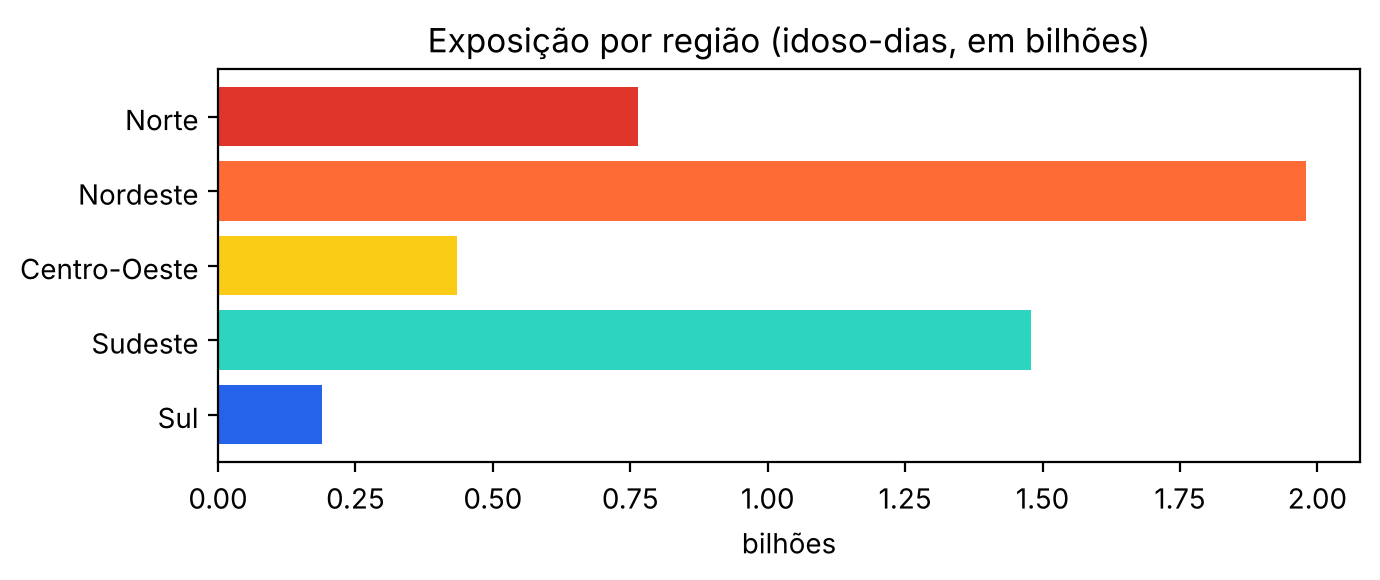

Norte           0.76 bi
Nordeste        1.98 bi
Centro-Oeste    0.44 bi
Sudeste         1.48 bi
Sul             0.19 bi
Name: idoso-dias, dtype: str

In [15]:
reg = dim_mun.merge(dim_uf, on='id_uf').merge(dim_regiao, on='id_regiao')[['cod_ibge','regiao','pop_65mais']]
idd = pm[pm.id_categoria==3].merge(reg, on='cod_ibge').groupby('regiao').idoso_dias.sum()
ordem_reg = ['Norte','Nordeste','Centro-Oeste','Sudeste','Sul']
cor_reg = {'Norte':'#e0352b','Nordeste':'#ff6b35','Centro-Oeste':'#facc15','Sudeste':'#2dd4bf','Sul':'#2563eb'}
plt.figure(figsize=(7,3))
vals = [idd.get(r,0)/1e9 for r in ordem_reg]
plt.barh(ordem_reg[::-1], vals[::-1], color=[cor_reg[r] for r in ordem_reg[::-1]])
plt.title('Exposição por região (idoso-dias, em bilhões)'); plt.xlabel('bilhões'); plt.tight_layout(); plt.show()
pd.Series({r: f'{idd.get(r,0)/1e9:.2f} bi' for r in ordem_reg}, name='idoso-dias')

E o painel que a secretaria usaria para começar a busca ativa, por município (exemplo com Mato Grosso):

In [16]:
nomes = {'Cuiabá':5103403,'Várzea Grande':5108402,'Sinop':5107909,'Rondonópolis':5107602,'Tangará da Serra':5107958,'Cáceres':5102504}
pmt = pm.merge(dim_tipo[['id_tipo_dia','tipo_dia']], on='id_tipo_dia')
linhas = []
for nome, cod in nomes.items():
    c = pmt[pmt.cod_ibge==cod]
    linhas.append({'municipio':nome,
                   'tipo_predominante': c.groupby('tipo_dia').dias.sum().idxmax(),
                   'idosos_65': int(dim_mun.set_index('cod_ibge').pop_65mais.get(cod,0)),
                   'dias_risco_alto': int(c[c.id_categoria==3].dias.sum())})
pd.DataFrame(linhas).sort_values('dias_risco_alto', ascending=False).reset_index(drop=True)

,municipio,tipo_predominante,idosos_65,dias_risco_alto
0,Cuiabá,Calor abafado,56173,842
1,Várzea Grande,Calor abafado,22054,842
2,Sinop,Quente e úmido,10674,392
3,Rondonópolis,Quente e úmido,19103,357
4,Tangará da Serra,Quente e úmido,7907,329
5,Cáceres,Calor abafado,8662,283


---
Dados: INMET (estações automáticas, 2023-2025) e IBGE (Censo 2022, tabela 9514). O data warehouse gerado aqui (`dados/dw/`) é o mesmo que alimenta o dashboard em `index.html`. Trabalho do grupo Cluster 2.0, turma 2TSCOR.